## 2107540 Data Science for Environmental and Sustainability
## Lecture 11 : Intro to Machine Learning II
### Done by : 6730084521 Chatrphol Ovanonchai

## Step 1: Import the dataset & Load Data

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
 StandardScaler,
 OneHotEncoder,
 PolynomialFeatures
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# Regression models
from sklearn.linear_model import (
 LinearRegression,
 Ridge,
 Lasso,
 ElasticNet
)
# Evaluation metrics
from sklearn.metrics import (
 mean_absolute_error,
 mean_squared_error,
 r2_score
)

In [40]:
## read data 
df = pd.read_csv("/Users/nubfightformydream/Documents/Documents/Intania 108 Courses/Year 3 Semester 1/2107540 Data Science for Environment and Sustainability/Lecture 10 Intro ML for Data Science/Measurement_summary.csv") # same data as lecture 10 

In [41]:
## check dataset
df.head()

,Measurement date,Station code,Address,Latitude,Longitude,SO2,NO2,O3,CO,PM10,PM2.5
0,2017-01-01 00:00,101,"19, Jong-ro 35ga-gil, Jongno-gu, Seoul, Republ...",37.572016,127.005008,0.004,0.059,0.002,1.2,73.0,57.0
1,2017-01-01 01:00,101,"19, Jong-ro 35ga-gil, Jongno-gu, Seoul, Republ...",37.572016,127.005008,0.004,0.058,0.002,1.2,71.0,59.0
2,2017-01-01 02:00,101,"19, Jong-ro 35ga-gil, Jongno-gu, Seoul, Republ...",37.572016,127.005008,0.004,0.056,0.002,1.2,70.0,59.0
3,2017-01-01 03:00,101,"19, Jong-ro 35ga-gil, Jongno-gu, Seoul, Republ...",37.572016,127.005008,0.004,0.056,0.002,1.2,70.0,58.0
4,2017-01-01 04:00,101,"19, Jong-ro 35ga-gil, Jongno-gu, Seoul, Republ...",37.572016,127.005008,0.003,0.051,0.002,1.2,69.0,61.0


In [42]:
df.info()

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nNumber of stations:")
print(df["Station code"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 647511 entries, 0 to 647510
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Measurement date  647511 non-null  str    
 1   Station code      647511 non-null  int64  
 2   Address           647511 non-null  str    
 3   Latitude          647511 non-null  float64
 4   Longitude         647511 non-null  float64
 5   SO2               647511 non-null  float64
 6   NO2               647511 non-null  float64
 7   O3                647511 non-null  float64
 8   CO                647511 non-null  float64
 9   PM10              647511 non-null  float64
 10  PM2.5             647511 non-null  float64
dtypes: float64(8), int64(1), str(2)
memory usage: 100.2 MB
Dataset shape: (647511, 11)

Missing values:
Measurement date    0
Station code        0
Address             0
Latitude            0
Longitude           0
SO2                 0
NO2                 0
O3               

## Step 2 : Exploratory Data Analysis (EDA)

In [43]:
df.describe()

,Station code,Latitude,Longitude,SO2,NO2,O3,CO,PM10,PM2.5
count,647511.000000,647511.000000,647511.000000,647511.000000,647511.000000,647511.000000,647511.000000,647511.000000,647511.000000
mean,113.000221,37.553484,126.989340,-0.001795,0.022519,0.017979,0.509197,43.708051,25.411995
std,7.211315,0.053273,0.078790,0.078832,0.115153,0.099308,0.405319,71.137342,43.924595
min,101.000000,37.452357,126.835151,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,107.000000,37.517528,126.927102,0.003000,0.016000,0.008000,0.300000,22.000000,11.000000
50%,113.000000,37.544962,127.004850,0.004000,0.025000,0.021000,0.500000,35.000000,19.000000
75%,119.000000,37.584848,127.047470,0.005000,0.038000,0.034000,0.600000,53.000000,31.000000
max,125.000000,37.658774,127.136792,3.736000,38.445000,33.600000,71.700000,3586.000000,6256.000000


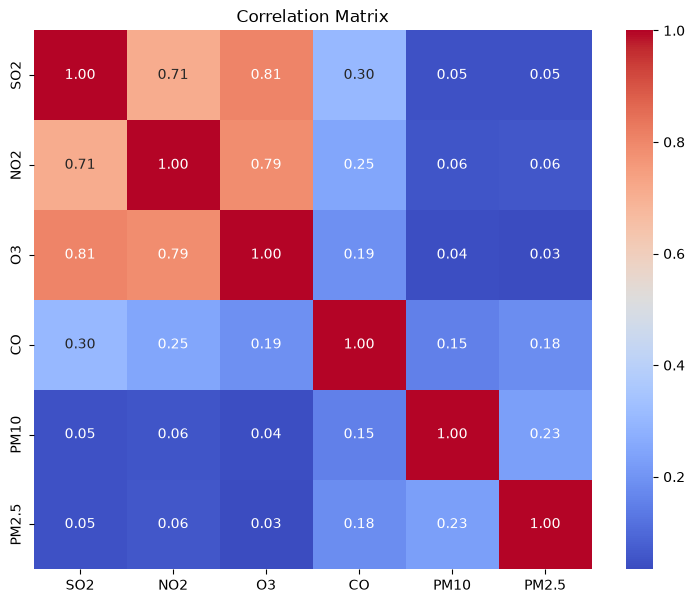

In [44]:
numeric_cols = ["SO2", "NO2", "O3", "CO", "PM10", "PM2.5"]
plt.figure(figsize=(9, 7))

## plot heatmap
## plot with numeric cols --> corr matrix 
sns.heatmap(data = df[numeric_cols].corr() , annot = True , cmap = "coolwarm" , fmt = ".2f")

## decorate graph
plt.title("Correlation Matrix")
plt.show()

## Step 3: Define Features and Target

In [45]:
# Numerical features
numeric_features = [
 "SO2",
 "NO2",
 "PM2.5",
 "CO",
 "PM10"
]
# Categorical features
categorical_features = [
 "Station code"
]
# Input features
X = df[numeric_features + categorical_features]
# Target variable
y = df["O3"]

## Step 4: Training/Testing sets

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
 X,
 y,
 test_size=0.2,
 random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (518008, 6)
X_test: (129503, 6)
y_train: (518008,)
y_test: (129503,)


## Step 5: Feature Scaling and Encoding

In [47]:
## numeric preprocessing -> StandardScaler
numeric_transformer = StandardScaler() 

# Categorical preprocessing -> OneHotEncoder
categorical_transformer = OneHotEncoder(
 handle_unknown="ignore",
 drop="first"
)
# Combine preprocessing --> ColumnTransformer
preprocessor = ColumnTransformer(
 transformers=[
 ("num", numeric_transformer, numeric_features),
 ("cat", categorical_transformer, categorical_features)
 ]
)

In [48]:
## fit and transform (scale)

X_train_processed = preprocessor.fit_transform(X_test) # train & scale
X_test_processed = preprocessor.transform(X_test) # just scale

print("Original shape:", X_train.shape)
print("Processed shape:", X_train_processed.shape)

Original shape: (518008, 6)
Processed shape: (129503, 29)


## Step 7: Multiple Linear Regression (MLR) 

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

## create pipeline for linear regression
linear_model = Pipeline(steps=[
 ("preprocessor", preprocessor),
 ("model", LinearRegression())
] , memory = None)

## train data with fit()
linear_model.fit(X_train, y_train)

## predict data
y_pred_linear = linear_model.predict(X_test)

In [50]:
## evaluate model
mae_linear = mean_absolute_error(y_true = y_test , y_pred = y_pred_linear)

rmse_linear = np.sqrt( mean_squared_error(y_true = y_test , y_pred = y_pred_linear) )

r2_linear = r2_score(y_true = y_test , y_pred = y_pred_linear)

print("Linear Regression")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R2:", r2_linear)

Linear Regression
MAE: 0.01878563590676938
RMSE: 0.06841418702246216
R2: 0.3515077304900588


## Step 8: Polynomial Features

In [51]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
 degree=2,
 include_bias=False
)


## test X
X_example = np.array([
 [2, 3],
 [4, 5]
])
X_poly = poly.fit_transform(X_example)
print(X_poly)
print(poly.get_feature_names_out(["x1", "x2"]))

[[ 2.  3.  4.  6.  9.]
 [ 4.  5. 16. 20. 25.]]
['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']


In [52]:
## build preprocessor
numeric_poly_transformer = Pipeline(steps=[
 ("poly", PolynomialFeatures(degree=2,include_bias=False)),
 ("scaler", StandardScaler())
])

poly_preprocessor = ColumnTransformer(
 transformers=[
 ("num", numeric_poly_transformer, numeric_features),
 ("cat", categorical_transformer, categorical_features)
 ]
)

In [53]:
## polynomial model
poly_model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", LinearRegression())
])
poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)

In [54]:
print("Polynomial Regression")
print("MAE:",
 mean_absolute_error(y_test, y_pred_poly))
print("RMSE:",
 np.sqrt(mean_squared_error(y_test, y_pred_poly)))
print("R2:",
 r2_score(y_test, y_pred_poly))

Polynomial Regression
MAE: 0.01627326277732696
RMSE: 0.038517126643958996
R2: 0.7944487011549763


In [55]:
## get RMSE for each degree
for degree in [1, 2, 3]:
    numeric_poly_transformer = Pipeline(steps=[
    ("poly", PolynomialFeatures(
        degree=degree,
        include_bias=False
    )),
    ("scaler", StandardScaler())
    ])
    
    current_preprocessor = ColumnTransformer(
    transformers=[
    ("num", numeric_poly_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
    ]
    )
    
    model = Pipeline(steps=[
    ("preprocessor", current_preprocessor),
    ("model", LinearRegression())
    ])
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print(f"Degree {degree} | RMSE: {rmse:.4f}")

Degree 1 | RMSE: 0.0684
Degree 2 | RMSE: 0.0385
Degree 3 | RMSE: 5.5156


## Step 9: Ridge Regression

In [56]:
ridge_model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)

In [57]:
## rmse for each alpha
alphas = [0.01, 0.1, 1, 10, 100]
for alpha in alphas:
 model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", Ridge(alpha=alpha))
 ])
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 rmse = np.sqrt(mean_squared_error(y_test, y_pred))
 print(f"Alpha: {alpha} | RMSE: {rmse:.4f}")

Alpha: 0.01 | RMSE: 0.0385
Alpha: 0.1 | RMSE: 0.0385
Alpha: 1 | RMSE: 0.0386
Alpha: 10 | RMSE: 0.0393
Alpha: 100 | RMSE: 0.0522


## Step 10: Lasso Regression 

In [58]:
lasso_model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", Lasso(
 alpha=0.1,
 max_iter=20000
 ))
])
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)

In [59]:
alphas = [0.001, 0.01, 0.1, 1, 10]
for alpha in alphas:
 model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", Lasso(
 alpha=alpha,
 max_iter=20000
 ))
 ])
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 rmse = np.sqrt(mean_squared_error(y_test, y_pred))
 print(f"Alpha: {alpha} | RMSE: {rmse:.4f}")

Alpha: 0.001 | RMSE: 0.0782
Alpha: 0.01 | RMSE: 0.0639
Alpha: 0.1 | RMSE: 0.0850
Alpha: 1 | RMSE: 0.0850
Alpha: 10 | RMSE: 0.0850


## Step 11: Elastic Net

In [60]:
elastic_model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", ElasticNet(
 alpha=0.1,
 l1_ratio=0.5,
 max_iter=20000
 ))
])
elastic_model.fit(X_train, y_train)
y_pred_elastic = elastic_model.predict(X_test)

In [61]:
ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
for ratio in ratios:
 model = Pipeline(steps=[
 ("preprocessor", poly_preprocessor),
 ("model", ElasticNet(
 alpha=0.1,
 l1_ratio=ratio,
 max_iter=20000
 ))
 ])
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 rmse = np.sqrt(mean_squared_error(y_test, y_pred))
 print(f"L1 Ratio: {ratio} | RMSE: {rmse:.4f}")

L1 Ratio: 0.1 | RMSE: 0.0594
L1 Ratio: 0.3 | RMSE: 0.0585
L1 Ratio: 0.5 | RMSE: 0.0651
L1 Ratio: 0.7 | RMSE: 0.0747
L1 Ratio: 0.9 | RMSE: 0.0850


## Step 12: Compare All Regression Models 

In [62]:
models = {
 "Linear Regression": linear_model,
 "Polynomial Regression": poly_model,
 "Ridge Regression": ridge_model,
 "Lasso Regression": lasso_model,
 "Elastic Net": elastic_model
}
results = []
predictions = {}
for name, model in models.items():
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 predictions[name] = y_pred
 results.append({
 "Model": name,
 "MAE": mean_absolute_error(y_test, y_pred),
 "RMSE": np.sqrt(
 mean_squared_error(y_test, y_pred)
 ),
 "R2": r2_score(y_test, y_pred)
 })
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
 by="RMSE",
 ascending=True
)
results_df.round(4)

,Model,MAE,RMSE,R2
1,Polynomial Regression,0.0163,0.0385,0.7944
2,Ridge Regression,0.0163,0.0386,0.7937
4,Elastic Net,0.0215,0.0651,0.4135
0,Linear Regression,0.0188,0.0684,0.3515
3,Lasso Regression,0.0213,0.0850,-0.0000


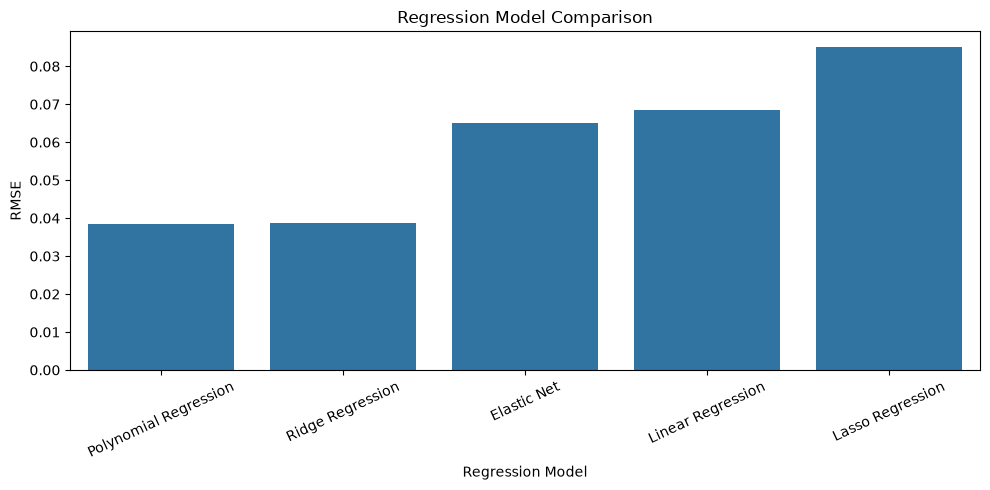

In [63]:
plt.figure(figsize=(10, 5))
sns.barplot(
 data=results_df,
 x="Model",
 y="RMSE"
)
plt.title("Regression Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("RMSE")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

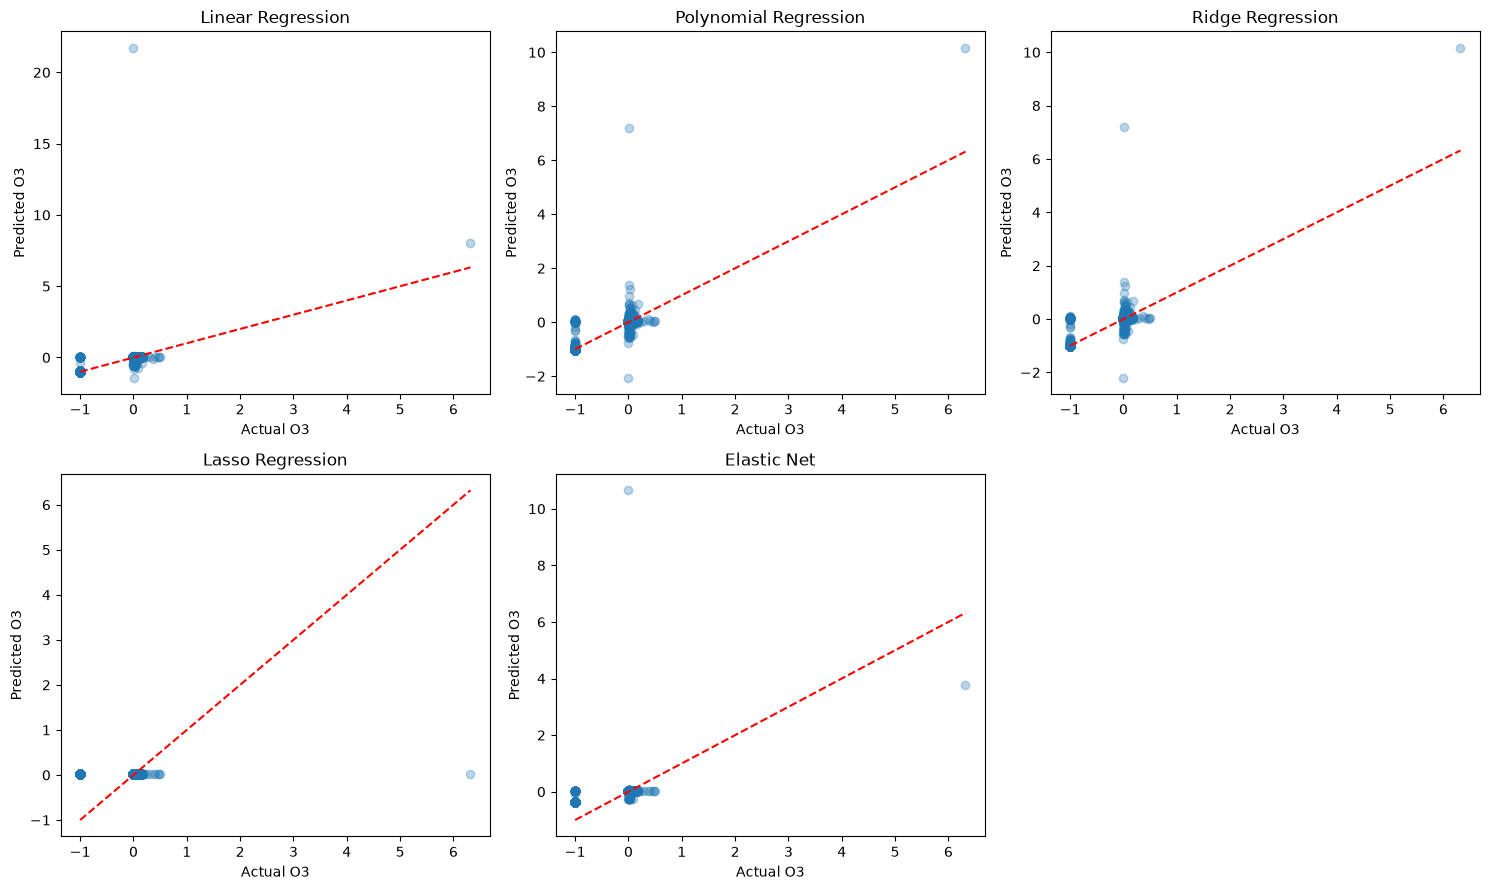

In [64]:
fig, axes = plt.subplots(
 2, 3,
 figsize=(15, 9)
)
axes = axes.flatten()

## plot y-test and y-pred then find trend line from each model 
for i, (name, y_pred) in enumerate(predictions.items()):
 axes[i].scatter(
 y_test,
 y_pred,
 alpha=0.3
 )
 axes[i].plot(
 [y_test.min(), y_test.max()],
 [y_test.min(), y_test.max()],
 "r--"
 )
 axes[i].set_title(name)
 axes[i].set_xlabel("Actual O3")
 axes[i].set_ylabel("Predicted O3")
axes[-1].axis("off")
plt.tight_layout()
plt.show()